# SVM simple example

## 0. Dependencies

In [11]:
import numpy as np                   # Dataset generation (random points), linear algebra (Gram matrix G, w, w0)
import matplotlib.pyplot as plt      # Scatter plots of the instances, decision line and margins
from cvxopt import matrix, solvers   # Quadratic programming solver for the SVM dual problem

## 1. Generating dataset

In [12]:
def generate_dataset(
    n_per_class: int = 10,
    center_neg: tuple[float, float] = (-2.0, -2.0),
    center_pos: tuple[float, float] = (2.0, 2.0),
    std: float = 0.8,
    seed: int = 42,
) -> tuple[np.ndarray, np.ndarray]:
    """Generate a small, linearly separable 2D binary classification dataset.

    Each class is a Gaussian cloud of points around its own center. With the
    default centers far apart relative to the standard deviation, the two
    clouds do not overlap, so a separating line exists.

    Args:
        n_per_class: Number of points sampled for each class.
        center_neg: Center (mean) of the class -1 cloud.
        center_pos: Center (mean) of the class +1 cloud.
        std: Standard deviation of each cloud (same in both directions).
        seed: Random seed, so the dataset is reproducible.

    Returns:
        A tuple (U, y) where U has shape (2 * n_per_class, 2) with the feature
        vectors u_k, and y has shape (2 * n_per_class,) with labels in {-1, +1}.
    """
    rng = np.random.default_rng(seed)
    U_neg = rng.normal(loc=center_neg, scale=std, size=(n_per_class, 2))
    U_pos = rng.normal(loc=center_pos, scale=std, size=(n_per_class, 2))

    U = np.vstack([U_neg, U_pos])
    y = np.hstack([-np.ones(n_per_class), np.ones(n_per_class)])
    return U, y


U, y = generate_dataset()
n, p = U.shape

print(f"Number of instances: {n}")
print(f"Number of features: {p}")
print(f"Class counts: -1 -> {np.sum(y == -1)}, +1 -> {np.sum(y == 1)}")
print("\nFirst instances of each class (x1, x2, y):")
print(np.column_stack([U, y])[[0, 1, 2, n // 2, n // 2 + 1, n // 2 + 2]])

Number of instances: 20
Number of features: 2
Class counts: -1 -> 10, +1 -> 10

First instances of each class (x1, x2, y):
[[-1.75622634 -2.83198728 -1.        ]
 [-1.39963904 -1.24754823 -1.        ]
 [-3.56082815 -3.04174361 -1.        ]
 [ 1.85211011  1.45525636  1.        ]
 [ 2.97803307  1.87637641  1.        ]
 [ 1.65733774  1.71829316  1.        ]]


## 2. Visualizing points

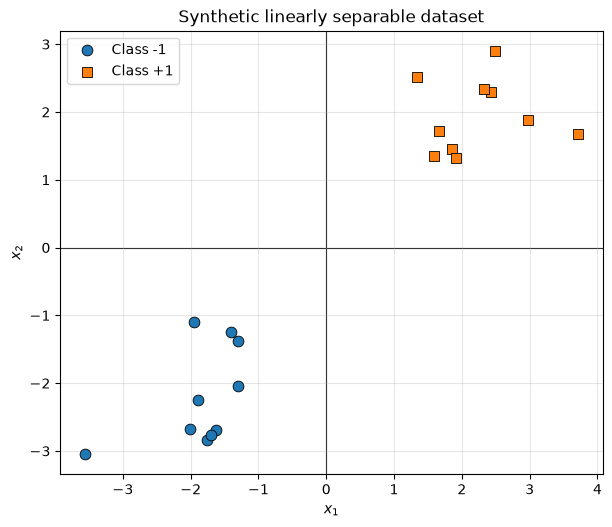

In [13]:
CLASS_STYLES = {
    -1: dict(color="tab:blue", marker="o", label="Class -1"),
    +1: dict(color="tab:orange", marker="s", label="Class +1"),
}


def plot_dataset(ax: plt.Axes, U: np.ndarray, y: np.ndarray) -> None:
    """Draw the instances of a 2D binary dataset on a matplotlib Axes.

    Each class gets its own color and marker (see CLASS_STYLES). The function
    only draws on the given Axes, so later steps can reuse it and add the
    decision line, the margins and the test instance on top of the same plot.

    Args:
        ax: Matplotlib Axes to draw on.
        U: Feature vectors, shape (n, 2).
        y: Labels in {-1, +1}, shape (n,).
    """
    for label, style in CLASS_STYLES.items():
        mask = y == label
        ax.scatter(U[mask, 0], U[mask, 1], s=60, edgecolors="black", linewidths=0.6, zorder=3, **style)

    ax.axhline(0, color="black", lw=0.8, zorder=1)
    ax.axvline(0, color="black", lw=0.8, zorder=1)
    ax.set_xlabel("$x_1$")
    ax.set_ylabel("$x_2$")
    ax.set_aspect("equal")
    ax.grid(alpha=0.3)


fig, ax = plt.subplots(figsize=(7, 7))
plot_dataset(ax, U, y)
ax.set_title("Synthetic linearly separable dataset")
ax.legend(loc="upper left")
plt.show()

## 3. Simples SVM algorithm implementation

### 3.1 Gram matrix G

In [14]:
# Gram matrix weighted by the labels: G[i, j] = y_i * y_j * (u_i . u_j)
Y_U = y[:, None] * U   # Row k is y_k * u_k
G = Y_U @ Y_U.T        # Entry (i, j) is (y_i u_i) . (y_j u_j) = y_i y_j (u_i . u_j)

print(f"G shape: {G.shape}")
print(f"G is symmetric: {np.allclose(G, G.T)}")
print(f"Smallest eigenvalue of G: {np.linalg.eigvalsh(G).min():.2e}  (>= 0 up to rounding -> G is positive semidefinite)")

G shape: (20, 20)
G is symmetric: True
Smallest eigenvalue of G: -1.34e-14  (>= 0 up to rounding -> G is positive semidefinite)


### 3.2 Solving the dual problem with `solvers.qp`

Dual problem of the hard-margin SVM:

$$\max_{z} \; \sum_k z_k - \frac{1}{2} z^\top G z \quad \text{s.t.} \quad z_k \ge 0, \; \sum_k y_k z_k = 0$$

`cvxopt.solvers.qp` solves $\min \frac{1}{2} z^\top P z + q^\top z$ s.t. $G_{ineq} z \le h$, $A z = b$, so we minimize the negative of the objective:

| cvxopt | SVM dual |
|---|---|
| $P$ | $G$ (professor's matrix) |
| $q$ | $-\mathbf{1}$ |
| $G_{ineq}, h$ | $-I, \; 0$ (encodes $z \ge 0$) |
| $A, b$ | $y^\top, \; 0$ (encodes $\sum_k y_k z_k = 0$) |

In [15]:
# cvxopt only accepts its own `matrix` type with float ("d") entries
P_qp = matrix(G)
q_qp = matrix(-np.ones(n))
G_qp = matrix(-np.eye(n))                 # -z <= 0  <=>  z >= 0
h_qp = matrix(np.zeros(n))
A_qp = matrix(y.reshape(1, -1))           # 1 x n row vector y^T
b_qp = matrix(0.0)

qp_solution = solvers.qp(P_qp, q_qp, G_qp, h_qp, A_qp, b_qp)
z = np.array(qp_solution["x"]).flatten()  # Optimal dual variables z_k (one per instance)

print(f"\nStatus: {qp_solution['status']}")
print(f"Dual objective (sum z - 1/2 z^T G z): {-qp_solution['primal objective']:.6f}")
print("\nz =")
for k in range(n):
    print(f"  z[{k:>2}] = {z[k]:.3e}   (y = {y[k]:+.0f})")

     pcost       dcost       gap    pres   dres
 0: -1.1987e+00 -1.7969e+00  4e+01  7e+00  1e+00
 1: -1.8865e-01 -3.8122e-01  3e+00  4e-01  9e-02
 2: -2.6352e-02 -2.8330e-01  3e-01  1e-16  7e-16
 3: -9.8573e-02 -1.3204e-01  3e-02  4e-17  3e-16
 4: -1.2390e-01 -1.2997e-01  6e-03  5e-17  3e-16
 5: -1.2706e-01 -1.2771e-01  6e-04  8e-17  3e-16
 6: -1.2753e-01 -1.2754e-01  2e-05  3e-17  2e-16
 7: -1.2754e-01 -1.2754e-01  2e-07  7e-17  3e-16
 8: -1.2754e-01 -1.2754e-01  2e-09  8e-17  3e-16
Optimal solution found.

Status: optimal
Dual objective (sum z - 1/2 z^T G z): 0.127542

z =
  z[ 0] = 7.564e-11   (y = -1)
  z[ 1] = 1.275e-01   (y = -1)
  z[ 2] = 3.473e-11   (y = -1)
  z[ 3] = 9.388e-11   (y = -1)
  z[ 4] = 6.961e-11   (y = -1)
  z[ 5] = 1.411e-07   (y = -1)
  z[ 6] = 2.588e-10   (y = -1)
  z[ 7] = 8.885e-11   (y = -1)
  z[ 8] = 8.066e-11   (y = -1)
  z[ 9] = 2.179e-10   (y = -1)
  z[10] = 2.488e-10   (y = +1)
  z[11] = 6.812e-11   (y = +1)
  z[12] = 2.430e-10   (y = +1)
  z[13] = 7.710

### 3.3 Weight vector w and bias w0

From the KKT conditions: $w = \sum_k z_k y_k u_k$. For any instance $k$ with $z_k > 0$, the constraint is active, $y_k (w \cdot u_k + w_0) = 1$, hence $w_0 = y_k - w \cdot u_k$ (using $y_k^2 = 1$). We use the instance with the largest $z_k$, which is surely strictly positive.

In [16]:
w = (z * y) @ U                 # w = sum_k z_k y_k u_k, shape (2,)

k_star = np.argmax(z)           # Instance with the largest dual variable
w0 = y[k_star] - w @ U[k_star]  # From y_k (w . u_k + w0) = 1

print(f"w  = ({w[0]:.4f}, {w[1]:.4f})")
print(f"w0 = {w0:.4f}   (computed from instance k = {k_star}, z_k = {z[k_star]:.3e})")
print(f"Margin width 2/||w|| = {2 / np.linalg.norm(w):.4f}")
print(f"\nDecision line: {w[0]:.4f} x1 {w[1]:+.4f} x2 {w0:+.4f} = 0")

w  = (0.3813, 0.3312)
w0 = -0.0531   (computed from instance k = 16, z_k = 1.275e-01)
Margin width 2/||w|| = 3.9599

Decision line: 0.3813 x1 +0.3312 x2 -0.0531 = 0


### 3.4 Support vectors

$SV = \{k : z_k > 0\}$. The solver is an interior-point method, so "zero" values come out as tiny positives (~1e-9). We therefore use a threshold relative to the largest $z_k$. As a check, every support vector must lie exactly on its margin: $y_k (w \cdot u_k + w_0) = 1$, and every estimate $w_0 = y_k - w \cdot u_k$ over $SV$ must agree.

In [17]:
sv_tol = 1e-5 * z.max()            # Below this, z_k is treated as numerically zero
SV = np.where(z > sv_tol)[0]       # Indices of the support vectors

margins = y * (U @ w + w0)         # y_k (w . u_k + w0): = 1 on the margin, > 1 beyond it
w0_estimates = y[SV] - U[SV] @ w   # One w0 estimate per support vector

print(f"Threshold for z_k > 0: {sv_tol:.1e}")
print(f"Number of support vectors: {len(SV)}\n")
print(f"{'k':>3} | {'x1':>7} | {'x2':>7} | {'y':>3} | {'z_k':>10} | {'y(w.u+w0)':>10} | SV?")
print("-" * 62)
for k in range(n):
    print(f"{k:>3} | {U[k, 0]:>7.3f} | {U[k, 1]:>7.3f} | {y[k]:>+3.0f} | {z[k]:>10.3e} | "
          f"{margins[k]:>10.4f} | {'yes' if k in SV else ''}")

print(f"\nw0 estimates over SV: {np.round(w0_estimates, 6)}  (spread = {np.ptp(w0_estimates):.1e})")
print(f"All instances satisfy y(w.u + w0) >= 1: {np.all(margins >= 1 - 1e-6)}")

Threshold for z_k > 0: 1.3e-06
Number of support vectors: 2

  k |      x1 |      x2 |   y |        z_k |  y(w.u+w0) | SV?
--------------------------------------------------------------
  0 |  -1.756 |  -2.832 |  -1 |  7.564e-11 |     1.6607 | 
  1 |  -1.400 |  -1.248 |  -1 |  1.275e-01 |     1.0000 | yes
  2 |  -3.561 |  -3.042 |  -1 |  3.473e-11 |     2.4183 | 
  3 |  -1.898 |  -2.253 |  -1 |  9.388e-11 |     1.5229 | 
  4 |  -2.013 |  -2.682 |  -1 |  6.961e-11 |     1.7092 | 
  5 |  -1.296 |  -1.378 |  -1 |  1.411e-07 |     1.0038 | 
  6 |  -1.947 |  -1.098 |  -1 |  2.588e-10 |     1.1593 | 
  7 |  -1.626 |  -2.687 |  -1 |  8.885e-11 |     1.5632 | 
  8 |  -1.705 |  -2.767 |  -1 |  8.066e-11 |     1.6197 | 
  9 |  -1.297 |  -2.040 |  -1 |  2.179e-10 |     1.2234 | 
 10 |   1.852 |   1.455 |  +1 |  2.488e-10 |     1.1351 | 
 11 |   2.978 |   1.876 |  +1 |  6.812e-11 |     1.7039 | 
 12 |   1.657 |   1.718 |  +1 |  2.430e-10 |     1.1479 | 
 13 |   2.426 |   2.292 |  +1 |  7.710e-11 |

## 4. Plotting the decision boundary and the margins

- Decision line (solid): $w \cdot u + w_0 = 0$
- Margin lines (dashed): $w \cdot u + w_0 = \pm 1$, which pass through the support vectors

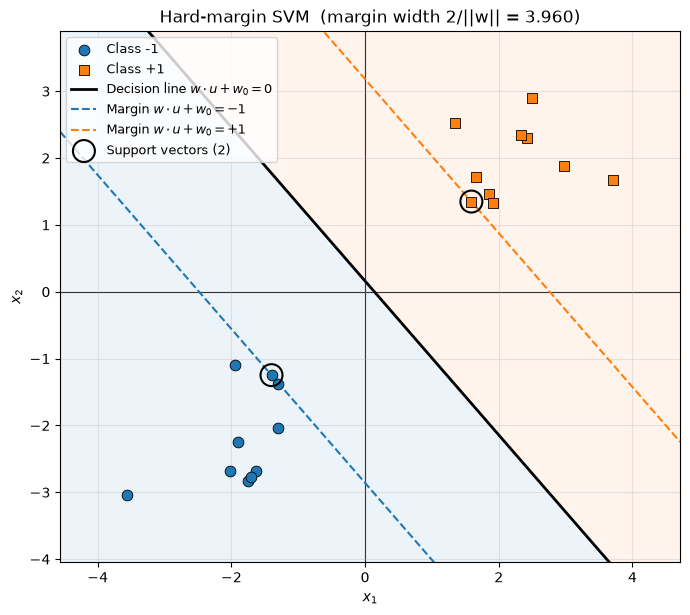

In [18]:
def plot_line(ax: plt.Axes, w: np.ndarray, w0: float, level: float, **style) -> None:
    """Draw the line w . u + w0 = level across the current x-limits of the Axes.

    Args:
        ax: Matplotlib Axes to draw on (its limits must already be set).
        w: Weight vector (w1, w2).
        w0: Bias.
        level: Right-hand side of the line equation (0 for the decision line, +-1 for the margins).
        **style: Extra keyword arguments forwarded to `ax.plot` / `ax.axvline`.
    """
    if abs(w[1]) > 1e-12:
        xs = np.array(ax.get_xlim())
        ax.plot(xs, (level - w0 - w[0] * xs) / w[1], **style)  # Solve w1 x1 + w2 x2 + w0 = level for x2
    else:
        ax.axvline((level - w0) / w[0], **style)                # Vertical line when w2 = 0


def plot_svm(ax: plt.Axes, U: np.ndarray, y: np.ndarray, w: np.ndarray, w0: float,
             SV: np.ndarray, pad: float = 1.0, extra_points: np.ndarray | None = None) -> None:
    """Draw the dataset, the SVM decision line, the margins and the support vectors.

    Args:
        ax: Matplotlib Axes to draw on.
        U: Feature vectors, shape (n, 2).
        y: Labels in {-1, +1}, shape (n,).
        w: Weight vector (w1, w2).
        w0: Bias.
        SV: Indices of the support vectors.
        pad: Extra space around the data when setting the axis limits.
        extra_points: Optional points, shape (m, 2), that are not drawn here but must
            fit inside the axis limits (e.g. test instances plotted afterwards).
    """
    # Fix the limits first so that the lines span the whole visible area
    all_points = U if extra_points is None else np.vstack([U, extra_points])
    x_min, y_min = all_points.min(axis=0) - pad
    x_max, y_max = all_points.max(axis=0) + pad
    ax.set_xlim(x_min, x_max)
    ax.set_ylim(y_min, y_max)

    # Light background showing on which side each class is predicted
    g1, g2 = np.meshgrid(np.linspace(x_min, x_max, 300), np.linspace(y_min, y_max, 300))
    side = np.sign(w[0] * g1 + w[1] * g2 + w0)
    ax.contourf(g1, g2, side, levels=[-2, 0, 2],
                colors=[CLASS_STYLES[-1]["color"], CLASS_STYLES[1]["color"]], alpha=0.08, zorder=0)

    plot_dataset(ax, U, y)

    plot_line(ax, w, w0, 0, color="black", lw=2, label="Decision line $w \\cdot u + w_0 = 0$")
    plot_line(ax, w, w0, -1, color=CLASS_STYLES[-1]["color"], lw=1.5, ls="--",
              label="Margin $w \\cdot u + w_0 = -1$")
    plot_line(ax, w, w0, +1, color=CLASS_STYLES[1]["color"], lw=1.5, ls="--",
              label="Margin $w \\cdot u + w_0 = +1$")

    # Support vectors: large hollow circles around the corresponding points
    ax.scatter(U[SV, 0], U[SV, 1], s=250, facecolors="none", edgecolors="black", linewidths=1.5,
               zorder=4, label=f"Support vectors ({len(SV)})")


fig, ax = plt.subplots(figsize=(8, 8))
plot_svm(ax, U, y, w, w0, SV)
ax.set_title(f"Hard-margin SVM  (margin width 2/||w|| = {2 / np.linalg.norm(w):.3f})")
ax.legend(loc="upper left", fontsize=9)
plt.show()

## 5. Predicting a new (test) instance

The trained model is just $(w, w_0)$. For a new instance $u$:

- Score: $f(u) = w \cdot u + w_0$
- Predicted class: $\hat{y} = \text{sign}(f(u))$
- Signed distance to the decision line: $f(u) / \|w\|$
- $|f(u)| \ge 1$ means $u$ lies on or beyond its margin line; $|f(u)| < 1$ means it falls inside the margin band (still classified, but with less confidence)

In [19]:
def predict(u: np.ndarray, w: np.ndarray, w0: float) -> tuple[int, float]:
    """Classify a single instance with a trained linear SVM.

    Args:
        u: Feature vector of the instance, shape (2,).
        w: Weight vector (w1, w2).
        w0: Bias.

    Returns:
        A tuple (y_hat, score) where score = w . u + w0 and y_hat = sign(score)
        in {-1, +1}. A score of exactly 0 (point on the decision line) is
        assigned to class +1 by convention.
    """
    score = float(w @ u + w0)
    y_hat = 1 if score >= 0 else -1
    return y_hat, score


u_test = np.array([1.0, -0.5])  # New instance, never seen during training

y_hat, score = predict(u_test, w, w0)
distance = score / np.linalg.norm(w)
position = "inside the margin band" if abs(score) < 1 else "on or beyond its margin line"

print(f"Test instance u = ({u_test[0]:.2f}, {u_test[1]:.2f})")
print(f"Score f(u) = w.u + w0 = {w[0]:.4f}*{u_test[0]:.2f} {w[1]:+.4f}*{u_test[1]:.2f} {w0:+.4f} = {score:.4f}")
print(f"Signed distance to the decision line: {distance:.4f}")
print(f"Position: {position}  (|f(u)| = {abs(score):.4f})")
print(f"\nPredicted class: {y_hat:+d}")

Test instance u = (1.00, -0.50)
Score f(u) = w.u + w0 = 0.3813*1.00 +0.3312*-0.50 -0.0531 = 0.1626
Signed distance to the decision line: 0.3220
Position: inside the margin band  (|f(u)| = 0.1626)

Predicted class: +1


## 6. Plotting the test instance

Same plot as step 4, with the test instance in a third color, annotated with its score $f(u)$, its predicted class and its distance $|f(u)| / \|w\|$ to the decision line.

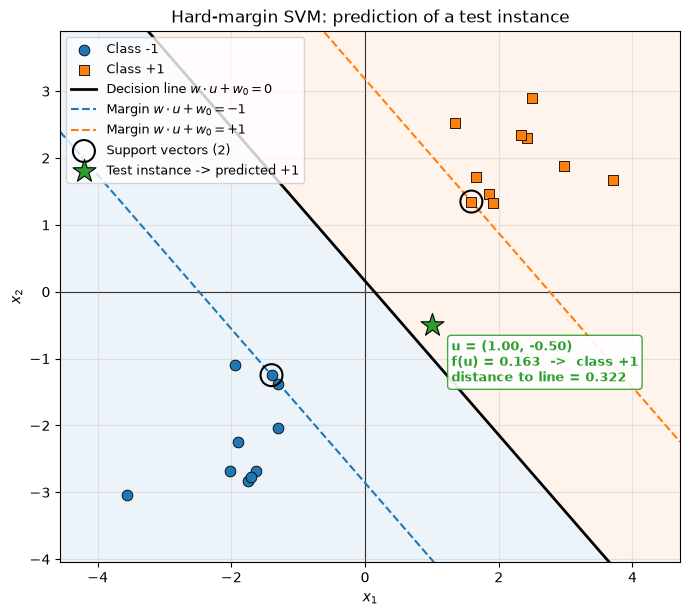

In [20]:
TEST_COLOR = "tab:green"

fig, ax = plt.subplots(figsize=(8, 8))
plot_svm(ax, U, y, w, w0, SV, extra_points=u_test.reshape(1, -1))

# Test instance: third color, star marker, annotated with its score, distance and predicted class
ax.scatter(*u_test, s=300, marker="*", color=TEST_COLOR, edgecolors="black", linewidths=0.8, zorder=5,
           label=f"Test instance -> predicted {y_hat:+d}")
ax.annotate(f"u = ({u_test[0]:.2f}, {u_test[1]:.2f})\n"
            f"f(u) = {score:.3f}  ->  class {y_hat:+d}\n"
            f"distance to line = {abs(distance):.3f}",
            u_test, xytext=(14, -10), textcoords="offset points", ha="left", va="top", fontsize=9, color=TEST_COLOR,
            fontweight="bold", bbox=dict(boxstyle="round", fc="white", ec=TEST_COLOR, alpha=0.9))

ax.set_title("Hard-margin SVM: prediction of a test instance")
ax.legend(loc="upper left", fontsize=9)
plt.show()